# 01 - EDA on the cleaned Tox21 data

Everything here reads `data/processed/tox21_clean.parquet` (C1) and the split files (C2). Figures go to `results/figures/`.

In [1]:
import sys; sys.path.insert(0, "../src")
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from rdkit import Chem
from tox.constants import CLEAN, TASKS, FIGURES, SPLIT_NAMES, RESULTS, PROCESSED
from tox.splits import load

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight"})
df = pd.read_parquet(CLEAN)
print(df.shape)
print(open(PROCESSED / "README.md").read())

(7709, 15)
# data/processed

- raw file: `https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz`
- raw md5: `2882d69e70bba0fec14995f26787cc25`
- raw rows: 7831, columns: NR-AR, NR-AR-LBD, NR-AhR, NR-Aromatase, NR-ER, NR-ER-LBD, NR-PPAR-gamma, SR-ARE, SR-ATAD5, SR-HSE, SR-MMP, SR-p53, mol_id, smiles
- unparseable smiles dropped: 8 (see dropped.csv)
- rows after standardization: 7823
- duplicate canonical smiles groups: 72 (114 rows merged)
- conflicting labels set to NaN: 44 (task, molecule) pairs (see conflicts.csv)
- clean rows: 7709, unique scaffolds: 2285
- standardization: largest fragment only, charges and stereo untouched



## Per-task labels: counts, positive rate, missing rate

               n_labelled  n_pos  pos_rate  missing_rate
NR-AR                7141    304     0.043         0.074
NR-AR-LBD            6652    235     0.035         0.137
NR-AhR               6444    763     0.118         0.164
NR-Aromatase         5718    286     0.050         0.258
NR-ER                6103    781     0.128         0.208
NR-ER-LBD            6851    343     0.050         0.111
NR-PPAR-gamma        6354    185     0.029         0.176
SR-ARE               5739    915     0.159         0.256
SR-ATAD5             6962    261     0.037         0.097
SR-HSE               6374    364     0.057         0.173
SR-MMP               5727    907     0.158         0.257
SR-p53               6673    419     0.063         0.134

overall missing rate: 0.17


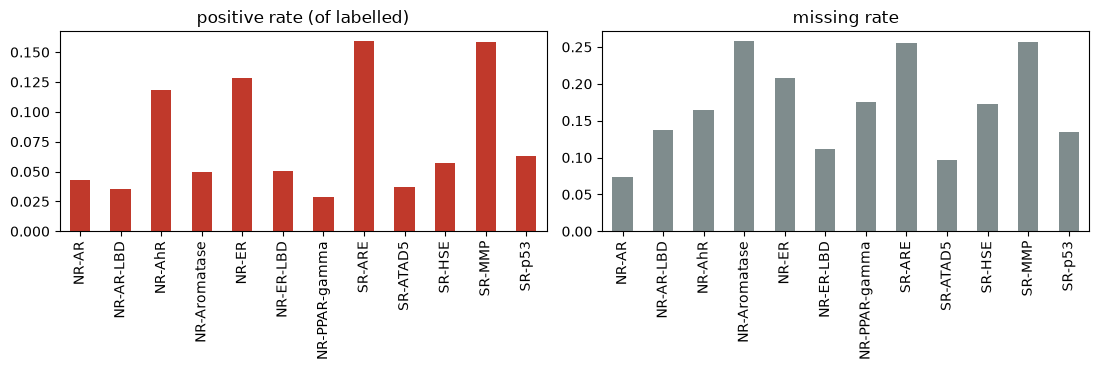

In [2]:
y = df[TASKS]
stats = pd.DataFrame({
    "n_labelled": y.notna().sum(),
    "n_pos": (y == 1).sum(),
    "pos_rate": y.mean(),            # mean ignores NaN -> rate among labelled
    "missing_rate": y.isna().mean(),
})
print(stats.round(3).to_string())
print("\noverall missing rate:", round(y.isna().to_numpy().mean(), 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
stats.pos_rate.plot.bar(ax=ax[0], color="#c0392b"); ax[0].set_title("positive rate (of labelled)")
stats.missing_rate.plot.bar(ax=ax[1], color="#7f8c8d"); ax[1].set_title("missing rate")
fig.tight_layout(); fig.savefig(FIGURES / "eda_label_rates.png")

Positives are rare (roughly 3-16%), so accuracy is useless here and PR-AUC has to be read against the positive rate. About 17% of the label matrix is missing, which is why every model masks missing labels instead of treating them as negatives.

## Label co-occurrence

Pearson (phi) correlation between endpoints, pairwise over molecules labelled for both tasks.

NR-AR   NR-AR-LBD    0.567
NR-ER   NR-ER-LBD    0.543
SR-ARE  SR-MMP       0.436
SR-HSE  SR-p53       0.374
SR-MMP  SR-p53       0.353
dtype: float64


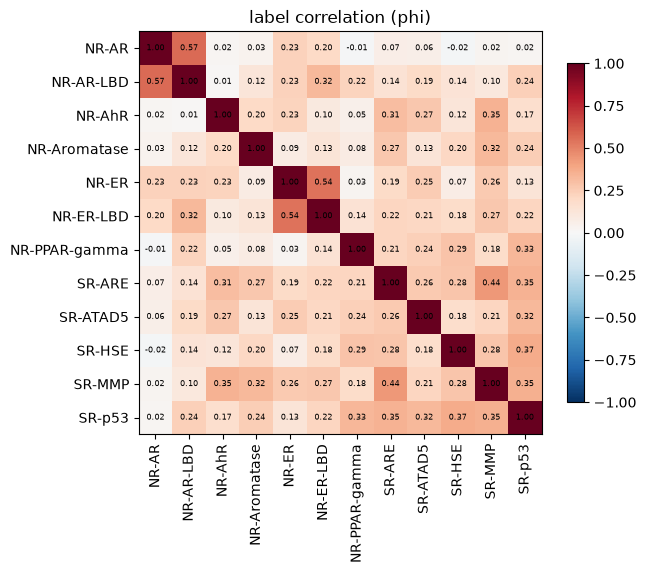

In [3]:
corr = y.corr(min_periods=100)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(12), TASKS, rotation=90); ax.set_yticks(range(12), TASKS)
for i in range(12):
    for j in range(12):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("label correlation (phi)")
fig.savefig(FIGURES / "eda_label_corr.png")
top = corr.where(np.triu(np.ones_like(corr, bool), 1)).stack().sort_values(ascending=False)
print(top.head(5).round(3))

The strongest pairs are the full-length receptor assay and its ligand-binding-domain version (NR-AR / NR-AR-LBD, NR-ER / NR-ER-LBD), which makes sense biologically. This shared signal is what a multi-task model (Phase 2) can use.

## Molecule size

count    7709.0
mean       18.3
std        10.9
min         1.0
25%        11.0
50%        16.0
75%        23.0
max       132.0
Name: smiles, dtype: float64
very small (<=3 heavy atoms): 57  very large (>=100): 8
['[I-]', '[Hg+2]', '[Ba+2]', '[TlH2+]', '[Cr+3]', '[Fe+2]', '[Co+2]', '[PbH2+2]', '[Fe+3]', '[Cu+2]']


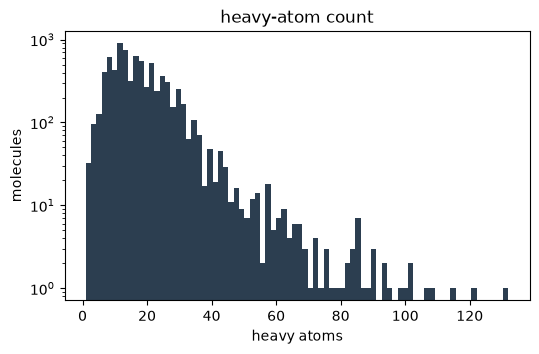

In [4]:
hac = df.smiles.map(lambda s: Chem.MolFromSmiles(s).GetNumHeavyAtoms())
print(hac.describe().round(1))
print("very small (<=3 heavy atoms):", (hac <= 3).sum(), " very large (>=100):", (hac >= 100).sum())
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(hac, bins=80, color="#2c3e50"); ax.set_xlabel("heavy atoms"); ax.set_ylabel("molecules"); ax.set_yscale("log")
ax.set_title("heavy-atom count"); fig.savefig(FIGURES / "eda_heavy_atoms.png")
print(df.loc[hac <= 1, "smiles"].head(10).tolist())

The tiny ones are mostly bare metal ions and halides (`[Hg+2]`, `[Cu+2]`, `[I-]`, ...) that are left after salt stripping, i.e. the metal *was* the active part of the salt. We keep them because the labels are real, but a 2048-bit Morgan fingerprint of a single atom is nearly empty, so no fingerprint model can say much about them. The few 100+ atom molecules are peptides/macrocycles and are rare.

## Scaffolds

unique scaffolds: 2285
acyclic molecules (scaffold ''): 1753
singleton scaffolds: 1730
scaffold
                       1753
c1ccccc1               1479
c1ccncc1                 88
c1ccc(Cc2ccccc2)cc1      81
c1ccc2ccccc2c1           68
Name: count, dtype: int64


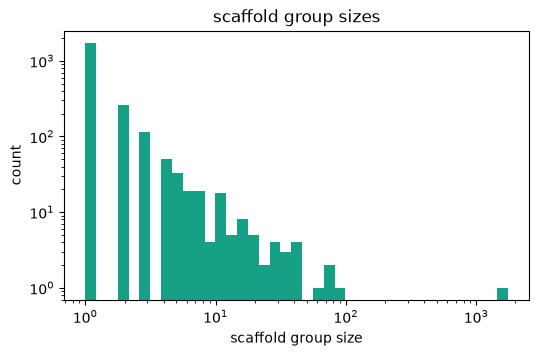

In [5]:
sizes = df.scaffold.value_counts()
print("unique scaffolds:", len(sizes))
print("acyclic molecules (scaffold ''):", sizes.get("", 0))
print("singleton scaffolds:", (sizes == 1).sum())
print(sizes.head(5))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(sizes, bins=np.logspace(0, np.log10(sizes.max()), 40), color="#16a085")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("scaffold group size"); ax.set_ylabel("count")
ax.set_title("scaffold group sizes"); fig.savefig(FIGURES / "eda_scaffold_sizes.png")

The biggest group is the acyclic one (`''`) plus benzene. Most scaffolds occur only once. That's why `scaffold_det` ends up with test sets made entirely of singleton scaffolds, which is a much harder test than the random split.

## Positive rate per task per split part

Needed to interpret PR-AUC: the random-classifier baseline for PR-AUC is the positive rate of that test set, not 0.5.

In [6]:
df_i = df.set_index("smiles")
rows = []
for name in SPLIT_NAMES:
    s = load(name)
    for role in ("train", "val", "test"):
        r = df_i.loc[s[role], TASKS].mean()
        rows.append({"split": name, "role": role, **r.to_dict()})
pr = pd.DataFrame(rows)
pr.to_csv(RESULTS / "eda_split_pos_rate.csv", index=False)
print(pr[pr.split.isin(["scaffold_det", "scaffold_s0", "random_s0"])].round(3).to_string(index=False))

       split  role  NR-AR  NR-AR-LBD  NR-AhR  NR-Aromatase  NR-ER  NR-ER-LBD  NR-PPAR-gamma  SR-ARE  SR-ATAD5  SR-HSE  SR-MMP  SR-p53
scaffold_det train  0.042      0.035   0.113         0.041  0.128      0.052          0.025   0.143     0.035   0.052   0.148   0.052
scaffold_det   val  0.043      0.040   0.133         0.100  0.112      0.039          0.039   0.254     0.047   0.092   0.202   0.113
scaffold_det  test  0.045      0.033   0.152         0.086  0.147      0.043          0.054   0.235     0.051   0.073   0.212   0.110
 scaffold_s0 train  0.038      0.028   0.102         0.040  0.118      0.044          0.024   0.142     0.031   0.051   0.146   0.054
 scaffold_s0   val  0.089      0.094   0.150         0.076  0.171      0.078          0.052   0.234     0.046   0.075   0.179   0.097
 scaffold_s0  test  0.035      0.042   0.223         0.110  0.174      0.074          0.047   0.250     0.081   0.092   0.252   0.101
   random_s0 train  0.042      0.034   0.120         0.050  0.

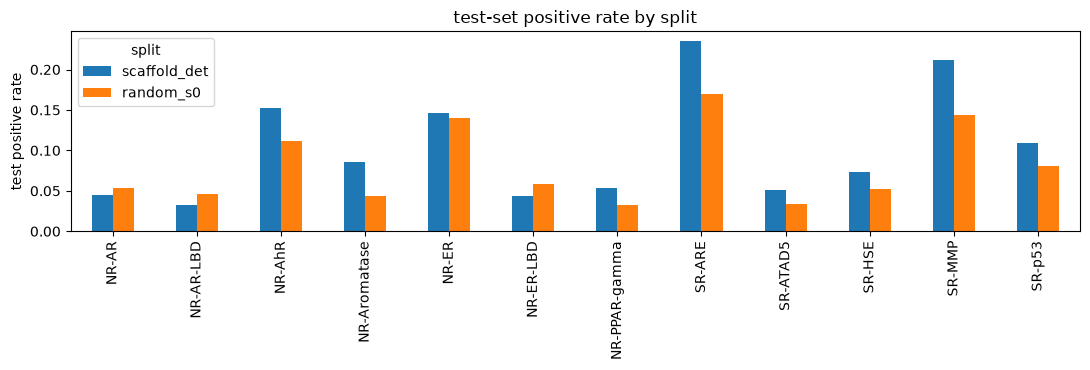

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.8))
sub = pr[pr.split.isin(["scaffold_det", "random_s0"]) & (pr.role == "test")].set_index("split")[TASKS].T
sub.plot.bar(ax=ax); ax.set_ylabel("test positive rate"); ax.set_title("test-set positive rate by split")
fig.tight_layout(); fig.savefig(FIGURES / "eda_split_pos_rate.png")

Positive rates shift between splits, especially on `scaffold_det` where the test set is small singleton scaffolds. So PR-AUC is only comparable between models on the **same** split, and we always report `pos_rate` next to it.